In [100]:
import pandas as pd
import seaborn as sns
import numpy as np
import matplotlib.pyplot as plt
df = pd.read_csv("insurance.csv")

import warnings

warnings.filterwarnings(
    "ignore",
    category=RuntimeWarning,
    message=".*encountered in matmul.*"
)

In [19]:
df.head()

,age,sex,bmi,children,smoker,region,charges
0,19,female,27.900,0,yes,southwest,16884.92400
1,18,male,33.770,1,no,southeast,1725.55230
2,28,male,33.000,3,no,southeast,4449.46200
3,33,male,22.705,0,no,northwest,21984.47061
4,32,male,28.880,0,no,northwest,3866.85520


In [20]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 1338 entries, 0 to 1337
Data columns (total 7 columns):
 #   Column    Non-Null Count  Dtype  
---  ------    --------------  -----  
 0   age       1338 non-null   int64  
 1   sex       1338 non-null   object 
 2   bmi       1338 non-null   float64
 3   children  1338 non-null   int64  
 4   smoker    1338 non-null   object 
 5   region    1338 non-null   object 
 6   charges   1338 non-null   float64
dtypes: float64(2), int64(2), object(3)
memory usage: 73.3+ KB


Отсутствующих значений нет.

In [24]:
df.describe()

,age,bmi,children,charges
count,1338.000000,1338.000000,1338.000000,1338.000000
mean,39.207025,30.663397,1.094918,13270.422265
std,14.049960,6.098187,1.205493,12110.011237
min,18.000000,15.960000,0.000000,1121.873900
25%,27.000000,26.296250,0.000000,4740.287150
50%,39.000000,30.400000,1.000000,9382.033000
75%,51.000000,34.693750,2.000000,16639.912515
max,64.000000,53.130000,5.000000,63770.428010


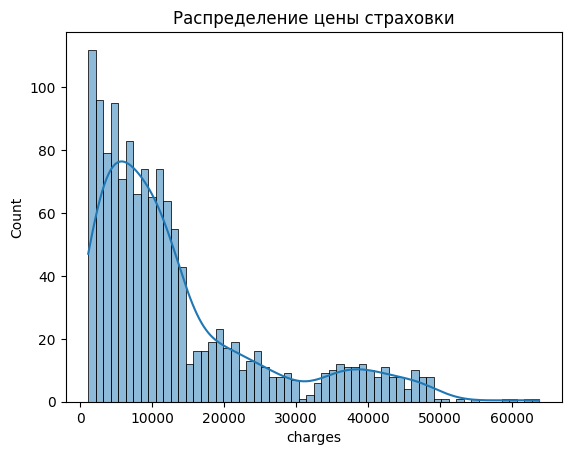

In [28]:
sns.histplot(df['charges'], bins = 60, kde = True)
plt.title("Распределение цены страховки")
plt.show()

На распределении таргета можно заметить правостороннюю асимметрию, это согласуется с данными, полученными при построении статистики.
Например:
    Разницей между медианным и средним значением. Среднее=13270 > медиана=9382 => выбросы в большую сторону.
    Распределением по четвертям. 75% клиентов имеют стоимость страховки меньше или равную 16639.

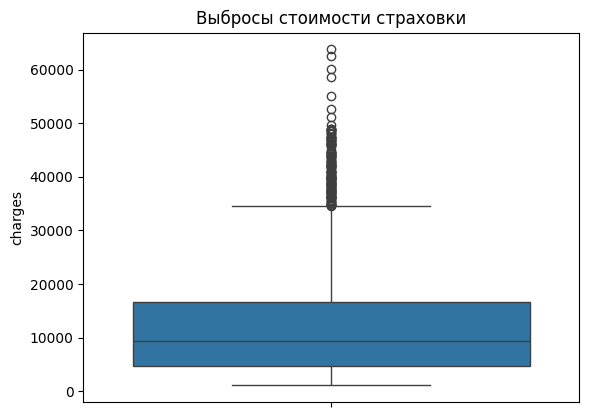

In [30]:
sns.boxplot(df['charges'])
plt.title("Выбросы стоимости страховки")
plt.show()

In [37]:
Q1 = df['charges'].quantile(0.25)
Q3 = df['charges'].quantile(0.75)
IQR = Q3 - Q1
lower_bound = Q1 - 1.5 * IQR
upper_bound = Q3 + 1.5 * IQR
outliers = df[(df['charges'] < lower_bound) | (df['charges'] > upper_bound)]

outliers.shape

(139, 7)

При помощи метода межквартального размаха, были найдены 139 возможных аномалий.

In [42]:
outliers[['age', 'bmi', 'smoker', 'children', 'charges']].head(20).sort_values(by=['age', 'bmi'])

,age,bmi,smoker,children,charges
161,18,36.850,yes,0,36149.48350
30,22,35.600,yes,0,35585.57600
82,22,37.620,yes,1,37165.16380
14,27,42.130,yes,0,39611.75770
34,28,36.400,yes,1,51194.55914
19,30,35.300,yes,0,36837.46700
158,30,35.530,yes,0,36950.25670
29,31,36.300,yes,2,38711.00000
23,34,31.920,yes,1,37701.87680
38,35,36.670,yes,1,39774.27630


Можно заметить, что люди с большой стоимостью страховки имеют ожирение и курят, так что можно считать, что это не выбросы, а закономерно большие стоимости.

Максимальные и минимальные значения других количественных фич-предикторов не кажутся аномальными.

In [55]:
df_new = df.copy()

df_new['sex'] = df_new['sex'].map({
    'male': 0,
    'female': 1
})
df_new['smoker'] = df_new['smoker'].map({
    'no': 0,
    'yes': 1
})

df_new = pd.get_dummies(df_new, columns=['region'], drop_first=True, dtype=int)

df_new.head()

,age,sex,bmi,children,smoker,charges,region_northwest,region_southeast,region_southwest
0,19,1,27.900,0,1,16884.92400,0,0,1
1,18,0,33.770,1,0,1725.55230,0,1,0
2,28,0,33.000,3,0,4449.46200,0,1,0
3,33,0,22.705,0,0,21984.47061,1,0,0
4,32,0,28.880,0,0,3866.85520,1,0,0


Чтобы не менять исходную бд, она была скопирована, а далее были обработаны категориальные переменные. Для регионов применила One-hot.

Разделим данные на train/test/val.

In [58]:
X = df_new.drop(columns=['charges'])
y = df_new['charges']
y_bins = pd.qcut(y, q=5, duplicates='drop')

from sklearn.model_selection import train_test_split

X_train, X_temp, y_train, y_temp, bins_train, bins_temp = train_test_split(
    X,
    y,
    y_bins,
    test_size=0.4,
    random_state=67,
    stratify=y_bins
)
X_val, X_test, y_val, y_test = train_test_split(
    X_temp,
    y_temp,
    test_size=0.5,
    random_state=67,
    stratify=bins_temp
)


Были отделены признаки от таргета, далее разбиение charges на 5 групп, чтобы потом использовать эти группы для стратифицированного разделения.

В качестве baseline решения буду просто предсказывать для всех среднее.

In [60]:
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score
baseline_value = y_train.mean()

y_train_baseline = np.full(len(y_train), baseline_value)
y_val_baseline = np.full(len(y_val), baseline_value)
y_test_baseline = np.full(len(y_test), baseline_value)

def print_metrics(y_true, y_pred, name):
    mae = mean_absolute_error(y_true, y_pred)
    rmse = np.sqrt(mean_squared_error(y_true, y_pred))
    r2 = r2_score(y_true, y_pred)

    print(name)
    print("MAE:", mae)
    print("RMSE:", rmse)
    print("R2:", r2)
    print()

print_metrics(y_train, y_train_baseline, "Baseline train")
print_metrics(y_val, y_val_baseline, "Baseline val")
print_metrics(y_test, y_test_baseline, "Baseline test")

Baseline train
MAE: 9046.631353431509
RMSE: 12096.908748214135
R2: 0.0

Baseline val
MAE: 8948.927042874819
RMSE: 11589.482345198352
R2: -6.13027914209141e-05

Baseline test
MAE: 9309.072322525682
RMSE: 12625.18687845609
R2: -0.000376652257384702



In [101]:
from sklearn.linear_model import LinearRegression

model = LinearRegression()

model.fit(X_train, y_train)

y_train_pred = model.predict(X_train)
y_val_pred = model.predict(X_val)
y_test_pred = model.predict(X_test)

print_metrics(y_train, y_train_pred, "Linear Regression train")
print_metrics(y_val, y_val_pred, "Linear Regression val")
print_metrics(y_test, y_test_pred, "Linear Regression test")

Linear Regression train
MAE: 4176.631319006984
RMSE: 6119.763481413739
R2: 0.7440704304548496

Linear Regression val
MAE: 4325.4320295749185
RMSE: 6016.140493150663
R2: 0.730515068961971

Linear Regression test
MAE: 4193.437618114235
RMSE: 5960.16015447714
R2: 0.7770518997077609



По результатам сравнения метрик на train, validation и test выраженного переобучения не обнаружено. Значения 0.744, 0.731, 0.777 очень близки.

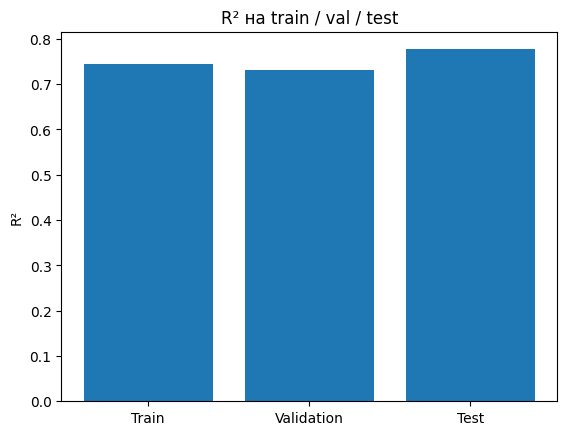

In [81]:
sets = ['Train', 'Validation', 'Test']
r2_values = [0.744, 0.731, 0.777]

plt.bar(sets, r2_values)
plt.ylabel('R²')
plt.title('R² на train / val / test')
plt.show()

In [86]:
class MyLinearRegression:
    def __init__(self, learning_rate=0.001, n_iterations=1000):
        self.learning_rate = learning_rate
        self.n_iterations = n_iterations

        self.weights = None
        self.bias = None

        self.loss_history = []

    def fit(self, X, y):
        X = np.array(X, dtype=float)
        y = np.array(y, dtype=float)

        n_samples, n_features = X.shape

        self.weights = np.zeros(n_features)
        self.bias = 0

        for i in range(self.n_iterations):
            y_pred = X @ self.weights + self.bias

            error = y_pred - y

            dw = (2 / n_samples) * (X.T @ error)
            db = (2 / n_samples) * np.sum(error)

            self.weights -= self.learning_rate * dw
            self.bias -= self.learning_rate * db

            mse = np.mean(error ** 2)
            self.loss_history.append(mse)

    def predict(self, X):
        X = np.array(X, dtype=float)

        return X @ self.weights + self.bias

Обучение происходит со следующими гиперпараметрами: шаг обучения(learning_rate), количество итераций обучения(n_iterations).

In [87]:
from sklearn.preprocessing import StandardScaler

scaler = StandardScaler()

X_train_scaled = X_train.copy()
X_val_scaled = X_val.copy()
X_test_scaled = X_test.copy()

columns_to_scale = ['age', 'bmi', 'children']

X_train_scaled[columns_to_scale] = scaler.fit_transform(
    X_train[columns_to_scale]
)

X_val_scaled[columns_to_scale] = scaler.transform(
    X_val[columns_to_scale]
)

X_test_scaled[columns_to_scale] = scaler.transform(
    X_test[columns_to_scale]
)

Сделано масштабирование для стабильной работы градиентного спуска и ускорения обучения модели. ВАЖНО: среднее и стандартное отклонение для масштабирования расчитывается на X_train, чтобы избежать data leak.

In [116]:
learning_rates = [0.001, 0.005, 0.01, 0.02, 0.4, 0.6]
iterations_list = [500, 1000, 2000]

for lr in learning_rates:
    for n_iter in iterations_list:
        model = MyLinearRegression(
            learning_rate=lr,
            n_iterations=n_iter
        )

        model.fit(X_train_scaled, y_train)

        y_val_pred = model.predict(X_val_scaled)

        rmse = np.sqrt(mean_squared_error(y_val, y_val_pred))

        print(lr, n_iter, rmse)

0.001 500 10106.099445281272
0.001 1000 8770.19051211755
0.001 2000 7484.077004358149
0.005 500 7067.721155130387
0.005 1000 6157.194365597928
0.005 2000 5973.75196583115
0.01 500 6156.617979577894
0.01 1000 5973.756796806942
0.01 2000 6003.724936988147
0.02 500 5973.766999598
0.02 1000 6003.752943806112
0.02 2000 6014.476345337259
0.4 500 6016.140492927586
0.4 1000 6016.140493150663
0.4 2000 6016.140493150663
0.6 500 6016.140493150653
0.6 1000 6016.140493150662
0.6 2000 6016.140493150662


Выбраны гиперпараметры 0,02 500, тк отличаются от лучших 0.005 2000 5973.75196583115 по ошибке на 0.01, но итераций в 4 раза меньше. Теперь можем обучить модель, измерить и посмотреть на ее качество на каждой итерации обучения.

In [109]:
my_model = MyLinearRegression(
    learning_rate=0.02,
    n_iterations=500
)

my_model.fit(X_train_scaled, y_train)

In [104]:
y_train_pred_my = my_model.predict(X_train_scaled)
y_val_pred_my = my_model.predict(X_val_scaled)
y_test_pred_my = my_model.predict(X_test_scaled)

In [110]:
print_metrics(y_train, y_train_pred_my, "My Linear Regression train")
print_metrics(y_val, y_val_pred_my, "My Linear Regression val")
print_metrics(y_test, y_test_pred_my, "My Linear Regression test")

My Linear Regression train
MAE: 4242.391957572946
RMSE: 6150.239907666284
R2: 0.7415150244405806

My Linear Regression val
MAE: 4396.502104666672
RMSE: 5973.756796806942
R2: 0.7342987353627344

My Linear Regression test
MAE: 4214.76715287335
RMSE: 5939.846278258457
R2: 0.7785690475877992



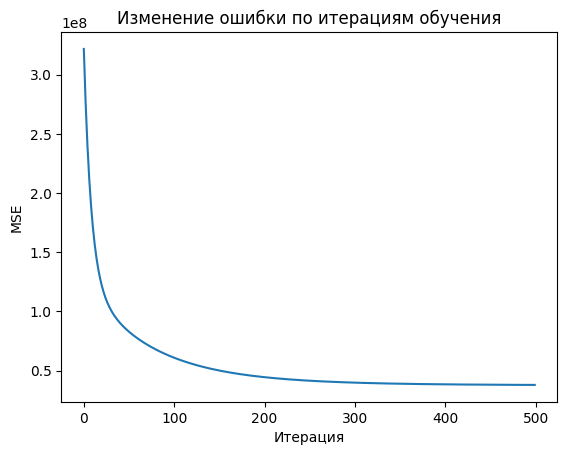

In [111]:
plt.plot(my_model.loss_history)

plt.xlabel('Итерация')
plt.ylabel('MSE')
plt.title('Изменение ошибки по итерациям обучения')

plt.show()

Сравним результаты:

In [114]:
comparison = pd.DataFrame({
    'Model': ['Sklearn LinearRegression', 'MyLinearRegression'],
    'MAE': [4193.44, 4214.77],
    'RMSE': [5960.16, 5939.85],
    'R2': [0.77705, 0.77857]
})

comparison

,Model,MAE,RMSE,R2
0,Sklearn LinearRegression,4193.44,5960.16,0.77705
1,MyLinearRegression,4214.77,5939.85,0.77857
